<a href="https://colab.research.google.com/github/mayurjadhav02/ML-P/blob/main/_car_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Used Car Price Prediction - India (Mini Project)
**Course:** CS3201L Machine Learning Laboratory | **Assignment 10: Mini Project**

**Problem:** Predict the selling price of a used car in India from its brand, age, kilometres driven, fuel type, transmission, ownership history and engine details. This is a **regression** problem.

**Workflow covered (as required by the lab manual):**
1. Data preprocessing (cleaning, missing values, outliers, encoding, scaling)
2. Feature engineering (car age, brand, cleaned mileage/engine/power)
3. Model building: Multiple Linear Regression, Polynomial Regression, kNN Regressor, Random Forest, Gradient Boosting
4. Model evaluation (R2, RMSE, MAE, cross-validation)
5. Advanced techniques (ensembles, hyperparameter tuning, log-transform of target)
6. Deployment (GitHub)

**Dataset:** CarDekho used-car listings from Kaggle (*Vehicle dataset from CarDekho*, by Nehal Birla).

## 1. Setup

In [ ]:
!pip install -q kagglehub

In [ ]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
LAKH = 100_000          # 1 lakh = 100,000 rupees
sns.set_style("whitegrid")

## 2. Load the Data
The cell below downloads the dataset from Kaggle using `kagglehub`. If that fails (for example, Kaggle asks for login), it falls back to a manual upload: download the dataset from Kaggle yourself, then upload **`Car details v3.csv`** when asked.

In [ ]:
# LOAD_CELL
csv_path = None
try:
    import kagglehub
    folder = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
    csvs = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    print("Files found:", [os.path.basename(c) for c in csvs])
    preferred = [c for c in csvs if "v3" in os.path.basename(c).lower()]
    csv_path = (preferred or csvs)[0]
except Exception as e:
    print("Automatic download failed:", e)
    from google.colab import files
    uploaded = files.upload()
    csv_path = list(uploaded.keys())[0]

print("Using file:", os.path.basename(csv_path))
raw = pd.read_csv(csv_path)
print("Shape:", raw.shape)
raw.head()

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Files found: ['car data.csv', 'car details v4.csv', 'CAR DETAILS FROM CAR DEKHO.csv', 'Car details v3.csv']
Using file: Car details v3.csv
Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## 3. Exploratory Data Analysis

In [ ]:
raw.info()
print("\nMissing values per column:")
print(raw.isnull().sum()[raw.isnull().sum() > 0])
print("Duplicate rows:", raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB

Missing values per column:
mileage      221
engine       221
max_power    215
torque       222
seats        221
dtype: int64
Duplicate rows: 1202


## 4. Data Preprocessing
Steps: standardise column names, remove duplicates, convert the price to rupees, clean text columns that contain units (e.g. `"19.4 kmpl"`, `"1248 CC"`, `"74 bhp"`), and encode ownership.

In [ ]:
df = raw.copy()

# 1. Standardise column names (works for the different CarDekho files)
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={"car_name": "name", "kms_driven": "km_driven",
                        "fuel_type": "fuel", "selling_type": "seller_type"})
df = df.drop(columns=[c for c in ["present_price", "torque"] if c in df.columns])  # not usable / messy

# 2. Remove duplicate listings
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}")

# 3. Price in rupees (some files store it in lakhs)
if df["selling_price"].median() < 1000:
    df["selling_price"] = df["selling_price"] * LAKH

# 4. Extract the number from text columns such as '19.4 kmpl', '1248 CC', '74 bhp'
for col in ["mileage", "engine", "max_power"]:
    if col in df.columns and not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col].astype(str).str.extract(r"([\d.]+)")[0], errors="coerce")

# 5. Ownership as an ordered number
if not pd.api.types.is_numeric_dtype(df["owner"]):
    owner_map = {"first": 1, "second": 2, "third": 3, "fourth": 4, "test": 0}
    def to_owner(s):
        s = str(s).lower()
        for k, v in owner_map.items():
            if k in s:
                return v
        return np.nan
    df["owner_num"] = df["owner"].apply(to_owner)
else:
    df["owner_num"] = df["owner"]

print("Missing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()

Duplicates removed: 1202
Missing values after cleaning:
mileage      208
engine       208
max_power    206
seats        208
dtype: int64


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,owner_num
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,1
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,2
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,3
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,1
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,1


In [ ]:
# 6. Remove clearly unrealistic records
before = len(df)
df = df[(df["km_driven"] <= 500_000) & (df["selling_price"] >= 20_000)].reset_index(drop=True)
print(f"Outlier rows removed: {before - len(df)} | Remaining: {len(df)}")
df[["selling_price", "km_driven", "year"]].describe().round(0)

Outlier rows removed: 3 | Remaining: 6923


,selling_price,km_driven,year
count,6923.0,6923.0,6923.0
mean,517315.0,73387.0,2013.0
std,519865.0,48178.0,4.0
min,29999.0,1.0,1983.0
25%,250000.0,40000.0,2011.0
50%,400000.0,70000.0,2014.0
75%,634500.0,100000.0,2017.0
max,10000000.0,500000.0,2020.0


## 5. Feature Engineering
- **`car_age`**: newest year in the data minus the manufacturing year (older cars are cheaper).
- **`brand`**: first word of the car name. Brands with fewer than 20 cars are grouped as `Other` (uses no price information).
- **Target transform**: the price is heavily right-skewed, so we model `log(1 + price)` and convert predictions back to rupees.

In [ ]:
REF_YEAR = int(df["year"].max())
df["car_age"] = REF_YEAR - df["year"]

df["brand"] = df["name"].astype(str).str.split().str[0].str.title()
rare = df["brand"].value_counts()
rare = rare[rare < 20].index
df["brand"] = df["brand"].replace(list(rare), "Other")
print("Brands:", df["brand"].nunique())
print(df["brand"].value_counts().head(10))

df["log_price"] = np.log1p(df["selling_price"])

Brands: 19
brand
Maruti        2164
Hyundai       1266
Mahindra       722
Tata           647
Honda          362
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     174
Name: count, dtype: int64


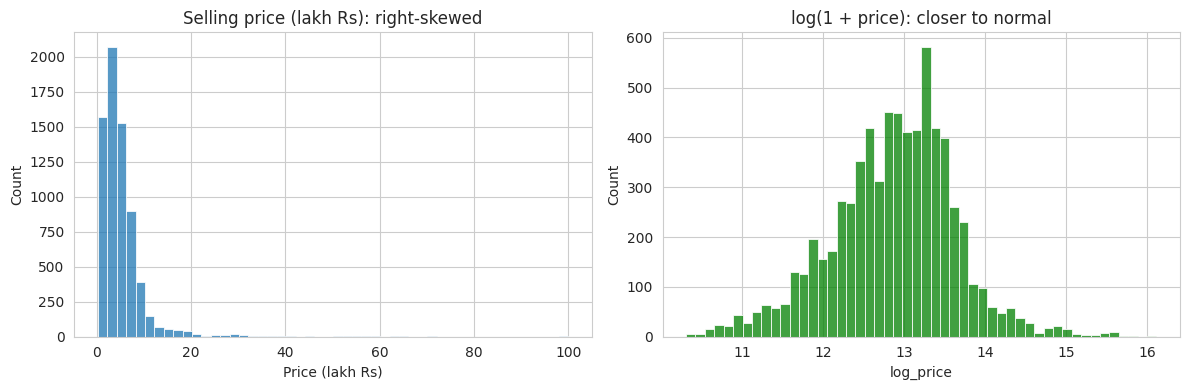

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["selling_price"] / LAKH, bins=50, ax=ax[0])
ax[0].set_title("Selling price (lakh Rs): right-skewed")
ax[0].set_xlabel("Price (lakh Rs)")
sns.histplot(df["log_price"], bins=50, ax=ax[1], color="green")
ax[1].set_title("log(1 + price): closer to normal")
plt.tight_layout()
plt.show()

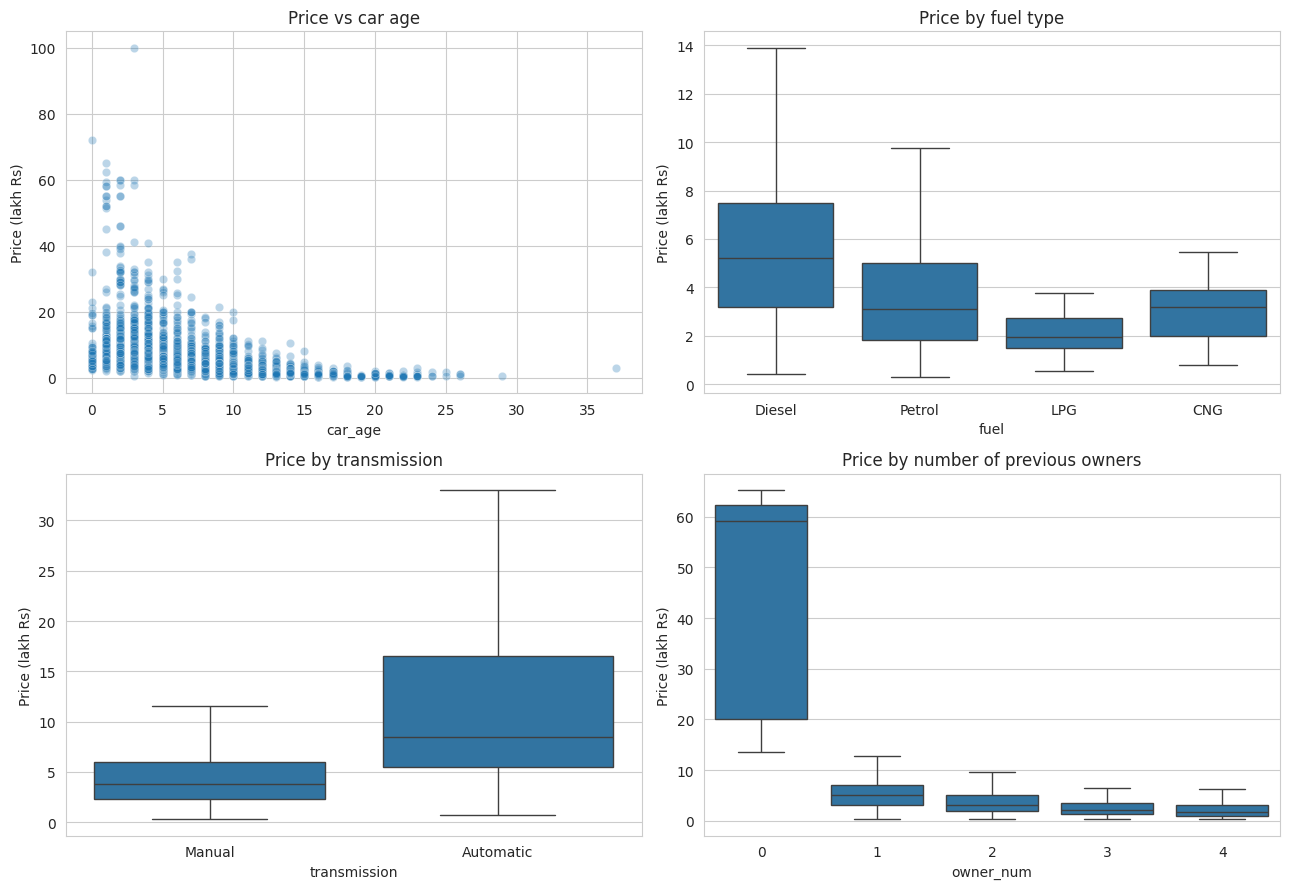

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(x="car_age", y=df["selling_price"] / LAKH, data=df, alpha=0.3, ax=ax[0, 0])
ax[0, 0].set_title("Price vs car age"); ax[0, 0].set_ylabel("Price (lakh Rs)")
sns.boxplot(x="fuel", y=df["selling_price"] / LAKH, data=df, showfliers=False, ax=ax[0, 1])
ax[0, 1].set_title("Price by fuel type"); ax[0, 1].set_ylabel("Price (lakh Rs)")
sns.boxplot(x="transmission", y=df["selling_price"] / LAKH, data=df, showfliers=False, ax=ax[1, 0])
ax[1, 0].set_title("Price by transmission"); ax[1, 0].set_ylabel("Price (lakh Rs)")
sns.boxplot(x="owner_num", y=df["selling_price"] / LAKH, data=df, showfliers=False, ax=ax[1, 1])
ax[1, 1].set_title("Price by number of previous owners"); ax[1, 1].set_ylabel("Price (lakh Rs)")
plt.tight_layout()
plt.show()

**Observations (check against your plots):** price falls with car age and with more previous owners, diesel and automatic cars tend to be costlier, and a few luxury cars create a long right tail.

Numeric features    : ['car_age', 'km_driven', 'owner_num', 'mileage', 'engine', 'max_power', 'seats']
Categorical features: ['brand', 'fuel', 'seller_type', 'transmission']


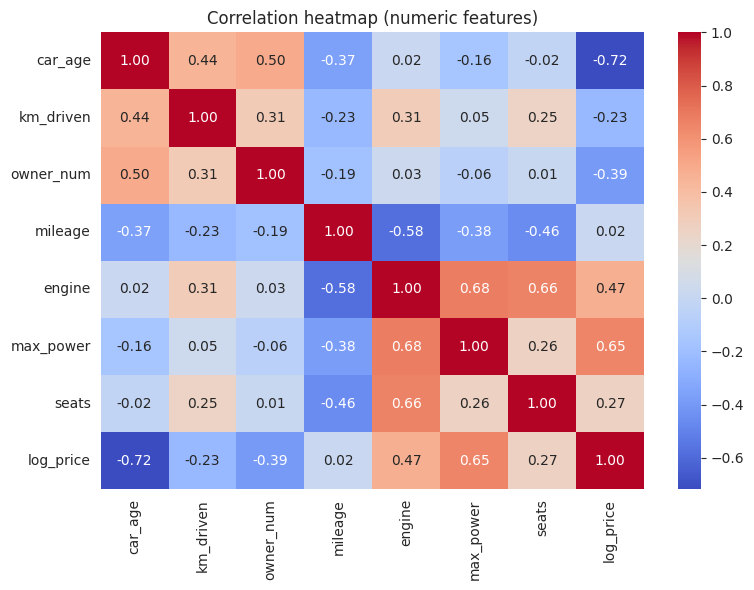

In [ ]:
num_candidates = ["car_age", "km_driven", "owner_num", "mileage", "engine", "max_power", "seats"]
cat_candidates = ["brand", "fuel", "seller_type", "transmission"]
num_cols = [c for c in num_candidates if c in df.columns]
cat_cols = [c for c in cat_candidates if c in df.columns]
print("Numeric features    :", num_cols)
print("Categorical features:", cat_cols)

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["log_price"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.show()

## 6. Train / Test Split
80% of the data is used for training and 20% is kept aside for the final test.

In [ ]:
X = df[num_cols + cat_cols]
y = df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5538, 11) | Test: (1385, 11)


## 7. Preprocessing Pipeline
All preprocessing lives inside a scikit-learn `Pipeline`, so it is fitted on the training data only (no data leakage) and the same steps are applied automatically at prediction time.
- Numeric: fill missing values with the median, then standardise (needed for kNN and linear models).
- Categorical: fill missing values with the most frequent value, then one-hot encode.

In [ ]:
def make_preprocessor(poly=False):
    num_steps = [("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())]
    if poly:
        num_steps.append(("poly", PolynomialFeatures(degree=2, include_bias=False)))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

## 8. Model Building and Evaluation
Every model is evaluated the same way:
- **R2** and **RMSE/MAE** on the test set, converted back to rupees
- **5-fold cross-validated R2** on the training set, to check stability

In [ ]:
results = []
trained = {}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, pipe):
    pipe.fit(X_train, y_train)
    pred_log = pipe.predict(X_test)
    pred = np.expm1(pred_log)
    actual = np.expm1(y_test)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1).mean()
    results.append({
        "Model": name,
        "Test R2 (log price)": r2_score(y_test, pred_log),
        "Test R2 (Rs)": r2_score(actual, pred),
        "RMSE (lakh Rs)": np.sqrt(mean_squared_error(actual, pred)) / LAKH,
        "MAE (lakh Rs)": mean_absolute_error(actual, pred) / LAKH,
        "CV R2 (log price)": cv_r2,
    })
    trained[name] = pipe
    print(f"{name:<38} R2(log)={results[-1]['Test R2 (log price)']:.4f}  "
          f"RMSE={results[-1]['RMSE (lakh Rs)']:.2f} lakh  MAE={results[-1]['MAE (lakh Rs)']:.2f} lakh  "
          f"CV R2={cv_r2:.4f}")

### Model 1: Multiple Linear Regression

In [ ]:
evaluate("Multiple Linear Regression",
         Pipeline([("prep", make_preprocessor()), ("reg", LinearRegression())]))

Multiple Linear Regression             R2(log)=0.8819  RMSE=2.26 lakh  MAE=1.00 lakh  CV R2=0.8818


### Model 2: Polynomial Regression (degree 2)
Squared and interaction terms of the numeric features capture curved relationships, such as the price falling quickly in the first few years and then slowly. A small Ridge penalty keeps the many extra coefficients stable.

In [ ]:
evaluate("Polynomial Regression (deg 2, Ridge)",
         Pipeline([("prep", make_preprocessor(poly=True)), ("reg", Ridge(alpha=1.0))]))

Polynomial Regression (deg 2, Ridge)   R2(log)=0.8982  RMSE=1.66 lakh  MAE=0.87 lakh  CV R2=0.8901


### Model 3: kNN Regressor
First choose K using cross-validation on the training set (not the test set). This links to Assignment 5: small K overfits, large K underfits.

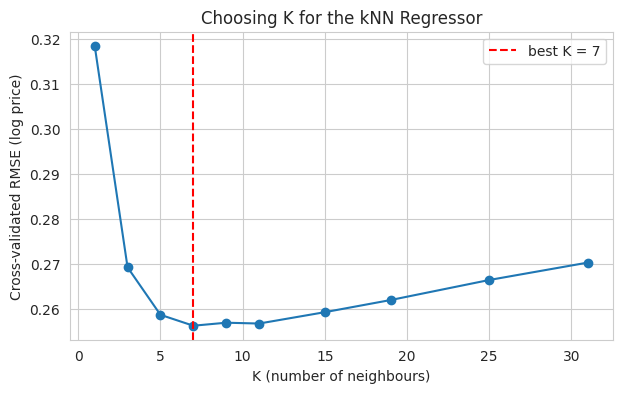

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15, 19, 25, 31]
k_rmse = []
for k in k_values:
    pipe = Pipeline([("prep", make_preprocessor()), ("reg", KNeighborsRegressor(n_neighbors=k, weights="distance"))])
    score = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    k_rmse.append(-score)

best_k = k_values[int(np.argmin(k_rmse))]
plt.figure(figsize=(7, 4))
plt.plot(k_values, k_rmse, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best K = {best_k}")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Cross-validated RMSE (log price)")
plt.title("Choosing K for the kNN Regressor")
plt.legend()
plt.show()

In [ ]:
evaluate(f"kNN Regressor (K={best_k})",
         Pipeline([("prep", make_preprocessor()),
                   ("reg", KNeighborsRegressor(n_neighbors=best_k, weights="distance"))]))

kNN Regressor (K=7)                    R2(log)=0.8922  RMSE=2.20 lakh  MAE=0.94 lakh  CV R2=0.8861


### Model 4: Random Forest

In [ ]:
evaluate("Random Forest",
         Pipeline([("prep", make_preprocessor()),
                   ("reg", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))]))

Random Forest                          R2(log)=0.9115  RMSE=1.43 lakh  MAE=0.76 lakh  CV R2=0.9084


### Model 5: Gradient Boosting

In [ ]:
evaluate("Gradient Boosting",
         Pipeline([("prep", make_preprocessor()),
                   ("reg", GradientBoostingRegressor(random_state=RANDOM_STATE))]))

Gradient Boosting                      R2(log)=0.9119  RMSE=1.56 lakh  MAE=0.81 lakh  CV R2=0.9064


## 10. Model Comparison

In [ ]:
res_df = pd.DataFrame(results).set_index("Model").round(4)
res_df.sort_values("Test R2 (log price)", ascending=False)

,Test R2 (log price),Test R2 (Rs),RMSE (lakh Rs),MAE (lakh Rs),CV R2 (log price)
Model,,,,,
Gradient Boosting,0.9119,0.9205,1.5599,0.8088,0.9064
Random Forest,0.9115,0.9327,1.4348,0.7596,0.9084
"Polynomial Regression (deg 2, Ridge)",0.8982,0.9100,1.6598,0.8747,0.8901
kNN Regressor (K=7),0.8922,0.8418,2.2004,0.9355,0.8861
Multiple Linear Regression,0.8819,0.8331,2.2605,0.9998,0.8818


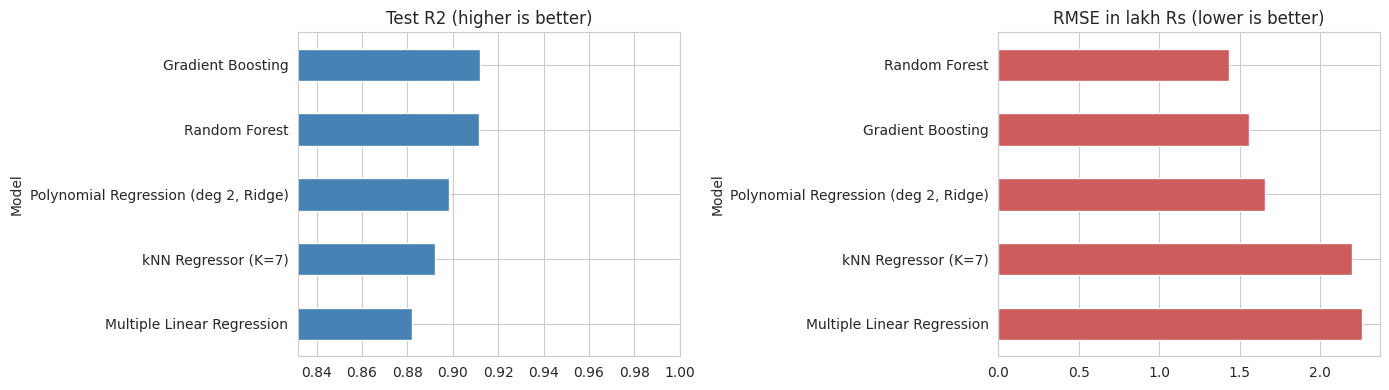

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
res_df["Test R2 (log price)"].sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Test R2 (higher is better)")
ax[0].set_xlim(res_df["Test R2 (log price)"].min() - 0.05, 1)
res_df["RMSE (lakh Rs)"].sort_values(ascending=False).plot(kind="barh", ax=ax[1], color="indianred")
ax[1].set_title("RMSE in lakh Rs (lower is better)")
plt.tight_layout()
plt.show()

## 11. Best Model: Predictions and Errors

Best model: Gradient Boosting


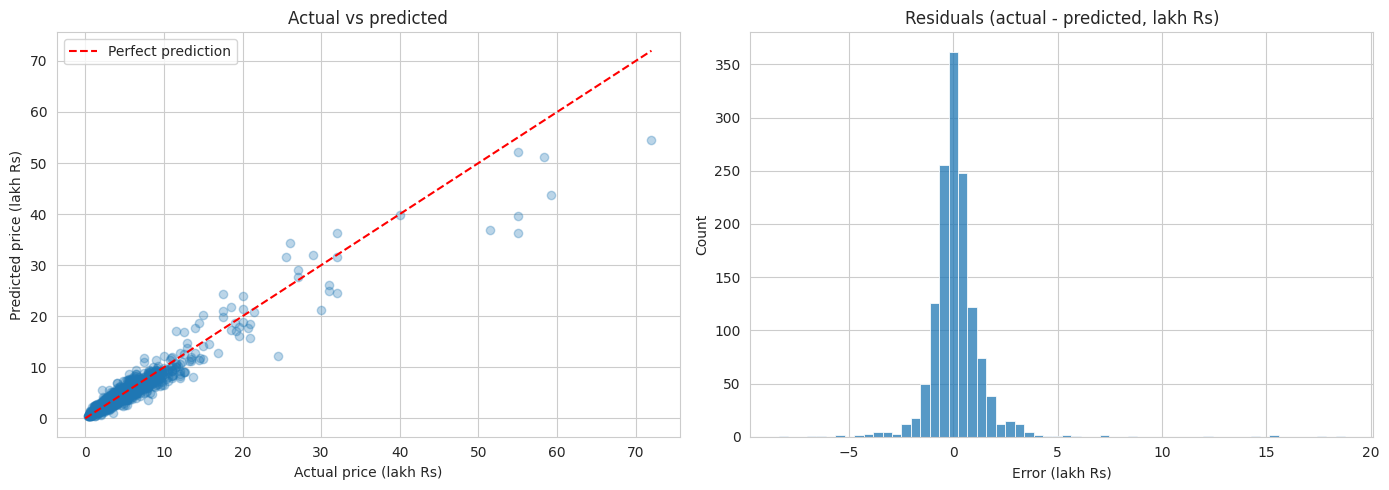

In [ ]:
best_name = res_df["Test R2 (log price)"].idxmax()
best_model = trained[best_name]
print("Best model:", best_name)

pred = np.expm1(best_model.predict(X_test))
actual = np.expm1(y_test)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(actual / LAKH, pred / LAKH, alpha=0.3)
lim = [0, max(actual.max(), pred.max()) / LAKH]
ax[0].plot(lim, lim, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual price (lakh Rs)")
ax[0].set_ylabel("Predicted price (lakh Rs)")
ax[0].set_title("Actual vs predicted")
ax[0].legend()

residuals = (actual - pred) / LAKH
sns.histplot(residuals, bins=60, ax=ax[1])
ax[1].set_title("Residuals (actual - predicted, lakh Rs)")
ax[1].set_xlabel("Error (lakh Rs)")
plt.tight_layout()
plt.show()

## 12. Feature Importance
Permutation importance measures how much the model's score drops when one feature is shuffled. A bigger drop means the feature matters more.

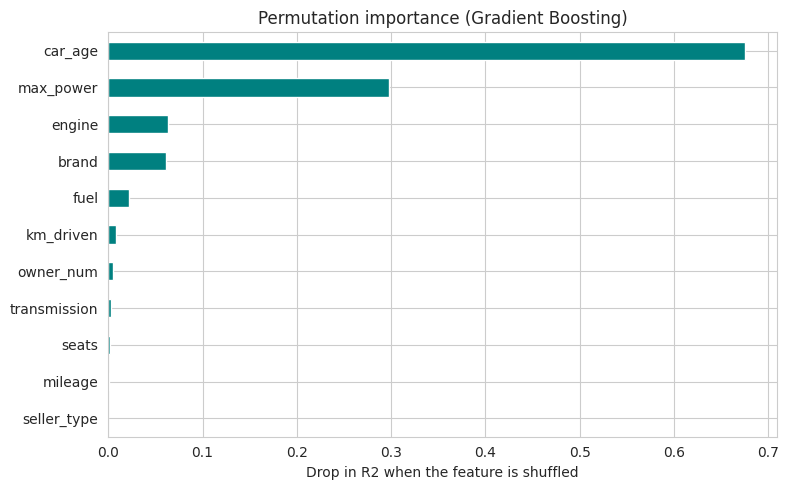

In [ ]:
imp = permutation_importance(best_model, X_test, y_test, n_repeats=5,
                             random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
imp_s.plot(kind="barh", figsize=(8, 5), color="teal")
plt.title(f"Permutation importance ({best_name})")
plt.xlabel("Drop in R2 when the feature is shuffled")
plt.tight_layout()
plt.show()

## 13. Predict the Price of Any Car (Demo)

In [ ]:
known_brands = set(df["brand"])

def predict_price(brand, year, km_driven, fuel, seller_type, transmission, owner,
                  mileage=None, engine=None, max_power=None, seats=None):
    row = {
        "car_age": REF_YEAR - year, "km_driven": km_driven, "owner_num": owner,
        "mileage": mileage, "engine": engine, "max_power": max_power, "seats": seats,
        "brand": brand.title() if brand.title() in known_brands else "Other",
        "fuel": fuel, "seller_type": seller_type, "transmission": transmission,
    }
    inp = pd.DataFrame([{c: row.get(c, np.nan) for c in num_cols + cat_cols}])
    price = np.expm1(best_model.predict(inp)[0])
    return price

p = predict_price("Maruti", 2016, 60000, "Petrol", "Individual", "Manual", 1,
                  mileage=21, engine=1197, max_power=83, seats=5)
print(f"Estimated price: Rs {p:,.0f}  ({p / LAKH:.2f} lakh)")

Estimated price: Rs 472,851  (4.73 lakh)


In [ ]:
# Try your own car. Edit the values below and run the cell.
p = predict_price(brand="Hyundai", year=2018, km_driven=45000, fuel="Diesel",
                  seller_type="Dealer", transmission="Manual", owner=1,
                  mileage=22, engine=1396, max_power=90, seats=5)
print(f"Estimated price: Rs {p:,.0f}  ({p / LAKH:.2f} lakh)")

Estimated price: Rs 799,112  (7.99 lakh)


## 14. Save the Model

In [ ]:
joblib.dump(best_model, "car_price_model.joblib")
print("Saved car_price_model.joblib")

# Optional: download it to your computer
# from google.colab import files
# files.download("car_price_model.joblib")

Saved car_price_model.joblib


## 15. Conclusion
*(Replace the points below with your actual numbers after running the notebook.)*

- The target was log-transformed because prices are right-skewed; predictions were converted back to rupees for reporting.
- Multiple Linear Regression gave a reasonable baseline; Polynomial Regression improved on it by capturing curved relationships such as depreciation with age.
- kNN performance depended strongly on K; K was chosen by cross-validation to avoid overfitting.
- Tree ensembles (Random Forest, Gradient Boosting) gave the best results because they capture non-linear effects and interactions between features (for example brand and age).
- Hyperparameter tuning improved Gradient Boosting further. Car age, engine power and brand were among the most important features.
- Limitations: the data is from listings (asking prices, not final sale prices), covers a limited period, and has little data for rare luxury cars.

**Possible future work:** add the car model name as a feature, try XGBoost/LightGBM, add city and condition data, and build a Streamlit web app for live price estimates.

---
## 16. Deployment on GitHub
1. In Colab: **File -> Save a copy in GitHub**, or **File -> Download -> .ipynb**.
2. Create a repository such as `used-car-price-prediction`.
3. Add the notebook, a `README.md` (problem, dataset, approach, results table, how to run), `requirements.txt` (`scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `joblib`, `kagglehub`) and screenshots of your key plots.
4. Add an **Open in Colab** badge to the README:
   `[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<your-username>/<repo-name>/blob/main/used_car_price_prediction.ipynb)`